# Baselines

L'expérience décrite dans le papier, ne propose pas de modèle baseline auquel comparer la nouvelle approche Online NMF. C'est l'objet de la poursuite que nous proposons. On suit 3 variables dans le temps, avec observations quotidiennes : les nouvelles contaminations confirmées, les nouveaux décès et les nouveux rétablissement du COVID-19. 

Voici plusieurs modélisations / prédicitons classiques possibles dans ce cas de figure :
- Prédicition naïve : on prédit la prochaine valeur par la dernière disponible $\hat{X}_{t+1|t} = X_t$ ;
- Prédiction avec moyenne mobile : on prédit la prochaine valeur comme moyenne des k dernières disponibles $\hat{X}_{t+1|t} = 1/k \sum_{j=0}^{k-1}{X_{t-j}}$;
- ARIMA(p, d, q) sur chaque série : un modèle par couple (variable, pays) ;
- VAR(p) sur le vecteur $X_t = (\text{confirmed}_t, \text{deaths}_t, \text{recovered}_t)^\top$.

À l'évidence, la faiblesse des 3 premiers modèles est qu'ils ne peuvent exploiter les intéractions entre les différentes variables et les différents pays. Le quatrième, quant à lui, exploite les intéractions entre les 3 variables pour un pays donné mais pas les intéractions entre pays. L'apprentissage d'un dictionnaire est le seul qui joue sur les deux types d'intéractions.

Nous comparerons les RMSE (par rapport aux valeurs effectives) des prédicitions obtenues par ces différentes approches avec celles des prédictions obtenues par le papier avec Online NMF.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import numpy as numpy

## Lecture et pré-traitement des données

In [3]:
confirmed_path = "COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
deaths_path = "COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv"
recovered_path = "COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_recovered_global.csv"

In [4]:
paths = [confirmed_path, deaths_path, recovered_path]
countries = ['Korea, South', 'China', 'US', 'Italy', 'Germany', 'Spain']
cutoff_date = "4/12/20" # Paper's dates: from Jan 19, 2020 to Apr. 12, 2020 -> missing Jan 19, 20, 21
val_date = "5/12/20" # 30 days after cutoff_date, to assess prediction accuracy

# Paramètres :
h = 30
k = 7

In [5]:
def reindex_data(df):
    df = df.T
    df.index.name = "date"
    df.index = pd.to_datetime(df.index, format="%m/%d/%y")
    return df

def preprocess_data(data_path: str, countries: list = countries, cutoff_date: str = cutoff_date):
    df = pd.read_csv(data_path)
    
    cols = list(df.columns)
    df = df[df["Country/Region"].isin(countries)].copy()
    df = df[[col for col in cols[:cols.index(cutoff_date)+1]]]
    df = df.drop(columns=["Lat", "Long", "Province/State"])
    df = df.groupby("Country/Region").sum(numeric_only=True)
    df = df.diff(axis=1).clip(lower=0)
    
    return reindex_data(df)

def get_validation_data(
        data_path: str,
        countries: list = countries,
        val_date: str = val_date
    ):
    df = pd.read_csv(data_path)
    cols = list(df.columns)

    df = df[df["Country/Region"].isin(countries)].copy()
    df = df[[col for col in cols[:cols.index(val_date)+1]]]
    df = df.drop(columns=["Lat", "Long", "Province/State"])
    df = df.groupby("Country/Region").sum(numeric_only=True)
    df = df.diff(axis=1).clip(lower=0)
    
    return reindex_data(df)

In [6]:
# Train data
confirmed_history = preprocess_data(paths[0])
deaths_history = preprocess_data(paths[1])
recovered_history = preprocess_data(paths[2])

In [7]:
# Extended data, including validation
confirmed_val = get_validation_data(paths[0])
deaths_val = get_validation_data(paths[1])
recovered_val = get_validation_data(paths[2])

In [ ]:
def predict_naive(history: pd.DataFrame) -> pd.DataFrame:
    start = history.index[-1] + pd.Timedelta(days=1)
    predictions = [confirmed_history.iloc[-1]] * 30
    forecast_dates = pd.date_range(start=start, periods=30, freq="D")
    naive_pred = pd.DataFrame(predictions, index=forecast_dates)
    naive_pred.index.name = "date"
    return pd.concat([history.tail(1), naive_pred])

def predict_ma7(history: pd.DataFrame) -> pd.DataFrame:
    history_copy = history.copy()
    predictions = []
    dates = []

    for _ in range(h):
        next_pred = history_copy.tail(k).mean()
        predictions.append(next_pred)

        next_date = history.index[-1] + pd.Timedelta(days=1)
        history_copy.loc[next_date] = next_pred

    ma7_pred = pd.DataFrame(
        predictions,
        index=pd.date_range(
            start=history.index[-1] + pd.Timedelta(days=1),
            periods=30,
            freq="D"
        )
    )
    
    return pd.concat([confirmed_history.tail(1), ma7_pred])

def predict_arima():
    return

def predict_var():
    return

In [13]:
def plot_rmse(
    pred: pd.DataFrame,
    true: pd.DataFrame,
    true_long: pd.DataFrame,
    countries: list = countries
) -> None:
    rmse_dict = {}
    fig, axes = plt.subplots(3, 2, figsize=(15, 12))

    for ax, country in zip(axes.flat, countries):
        y_true = true[country]
        y_pred = pred[country]
        rmse = root_mean_squared_error(y_true, y_pred)
        rmse_dict[country] = rmse

        ax.plot(true_long.index, true_long[country], label="actual")
        ax.plot(pred.index, pred[country], label="predicted")

        ax.legend()
        ax.set_title(f"{country} – RMSE = {rmse:.2f}")

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    return rmse_dict

## Graphes des séries

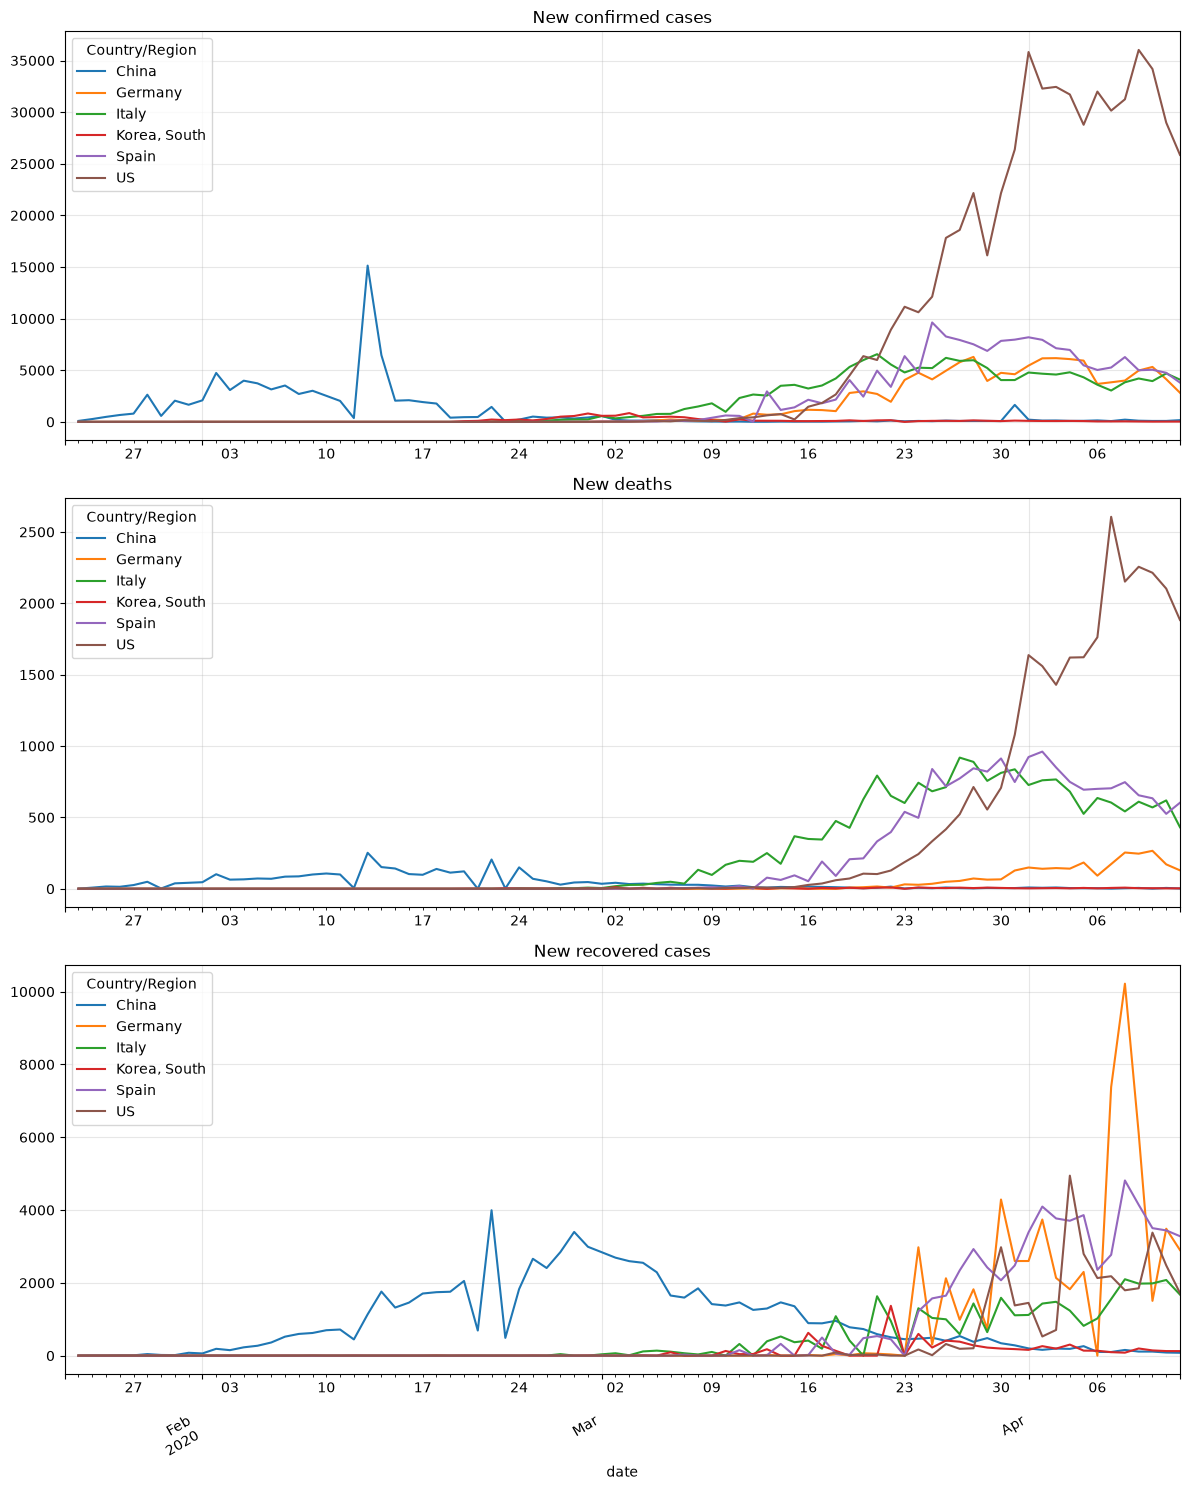

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10,14))

data = {
    "New confirmed cases": confirmed_history,
    "New deaths": deaths_history,
    "New recovered cases": recovered_history
}

for ax, (title, df) in zip(axes, data.items()):
    df.plot(ax=ax, legend=True)
    ax.set_title(title)
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Prédiction naïve

Prédiction : $\hat{X}_{t+1|t} = X_t$ et par extrapolation : $\forall h \geq 0, \quad \hat{X}_{t+h|t} = X_t$

In [11]:
# Data not seen during training
sub_confirmed_val = confirmed_val[confirmed_val.index >= "2020-04-12"] # Compare predictions with this
naive_pred = predict_naive(confirmed_history)

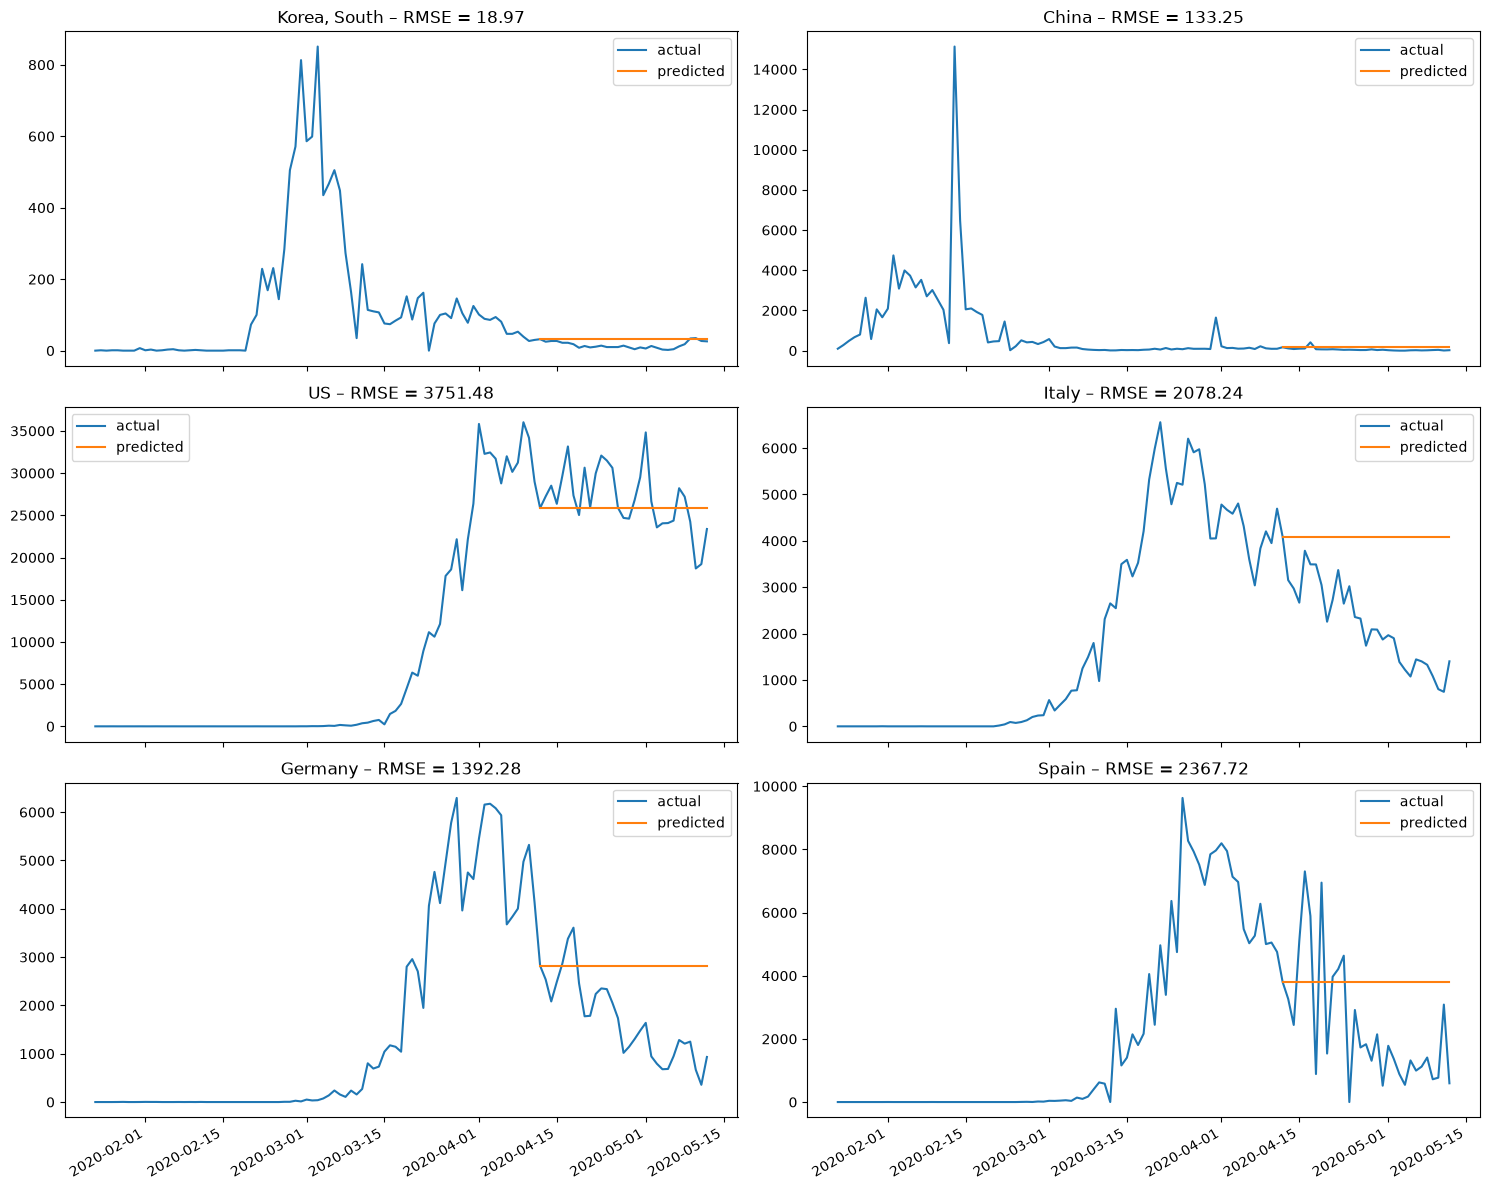

{'Korea, South': 18.96686414470961,
 'China': 133.25152059896158,
 'US': 3751.477420791664,
 'Italy': 2078.240082066958,
 'Germany': 1392.2826812526719,
 'Spain': 2367.7209608370445}

In [14]:
plot_rmse(naive_pred, sub_confirmed_val, confirmed_val)

## Prédiction avec moyenne mobile
Prédiction : $\hat{X}_{t+1|t} = \frac{1}{k} \sum_{j=0}^{k-1}{X_{t-j}}$ et par extension : $\hat{X}_{t+h|t} = \frac{1}{k} \sum_{j=0}^{k-1}{\hat{X}_{t-j}}$ où $\hat{X}_{i} = X_{i}$ si $X_{i}$ est observable.

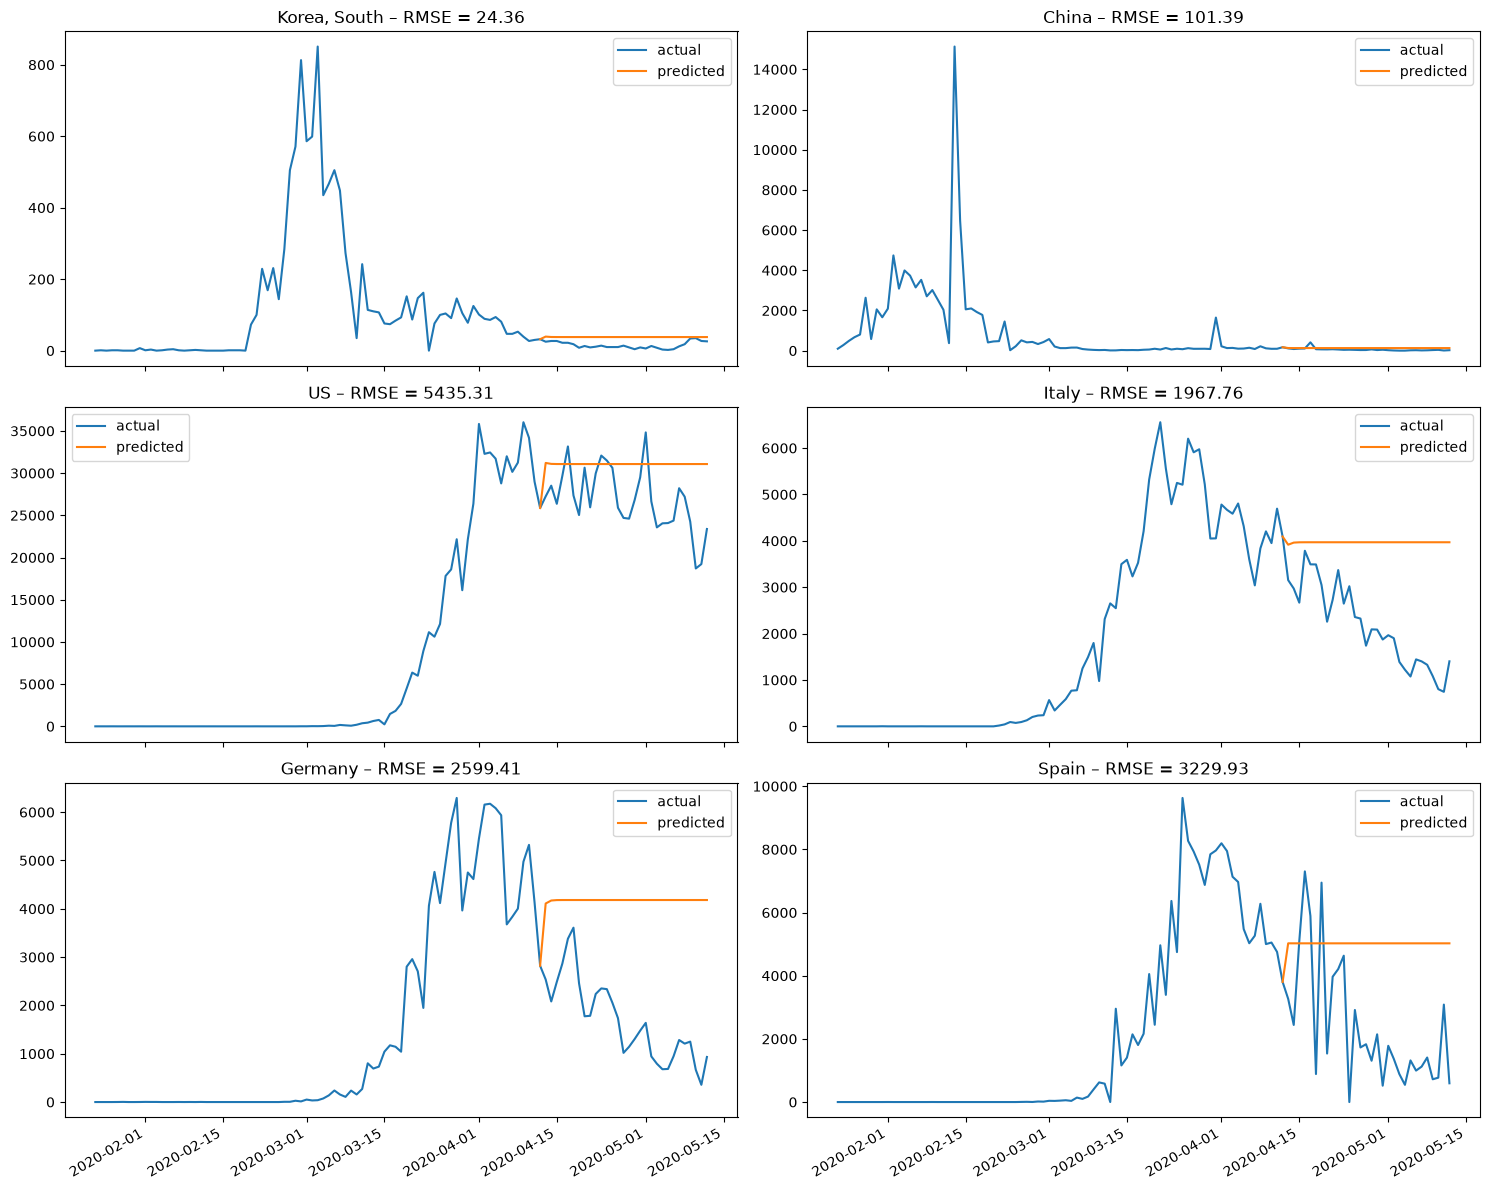

{'Korea, South': 24.35746890923737,
 'China': 101.38841567926643,
 'US': 5435.305869470354,
 'Italy': 1967.7639609206062,
 'Germany': 2599.4076468219378,
 'Spain': 3229.927310204407}

In [15]:
pred_ma7 = predict_ma7(history=confirmed_history)
plot_rmse(pred_ma7, sub_confirmed_val, confirmed_val)

## Prédiction avec ARIMA(p,d,q) sur chaque série

Pour un pays et une variable donnée, on définit l'approche pour identifier l'ordre et les coefficients du modèle :
1. **Sationnarité** : on utilise **ADF** (qui teste si le processus possède une racine unitaire) et **KPSS** (qui teste si le processus est stationnaire autour d'une tendeance déterministe) au seuil de $5%$. On dérive la série tant que $p_{\text{ADF}} \geq 0.05$ ou $p_{\text{KPSS}} < 0.05$.
2. **Identification** : après d différenciations, une ACF et un PACF nous permettent d'identifier les ordres p et q candidats.
3. **Sélection** : le but étant de garder un modèle simple en raison du faible nombre de données, on calcule un BIC pour tous les ordres candidats et on retient le modèle avec le BIC le plus faible.
4. **Diagnostics** : une fois le modèle choisi, on vérifie que ses résidus ressemblent plus ou moin à un bruit blanc (pas d'autocorrélation, normalité, etc.)
5. **Prédiction** : après vérification, on prédit récursivement les prochaines valeurs de la série sur 30 jours

In [21]:
country = "Spain"
series = confirmed_history[country]

### Stationnarité

In [29]:
from statsmodels.tsa.stattools import adfuller, kpss

In [30]:
def test_stationarity(x):
    x = x.dropna()

    adf_pvalue = adfuller(x)[1]
    kpss_pvalue = kpss(x, regression="c")[1]

    return adf_pvalue, kpss_pvalue

/var/folders/cb/smr6m6xx6r99ts8034bf09pr0000gn/T/ipykernel_63905/3171770333.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_pvalue = adfuller(x)[1]
/var/folders/cb/smr6m6xx6r99ts8034bf09pr0000gn/T/ipykernel_63905/3171770333.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_pvalue = kpss(x, regression="c")[1]
/var/folders/cb/smr6m6xx6r99ts8034bf09pr0000gn/T/ipykernel_63905/3171770333.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). I

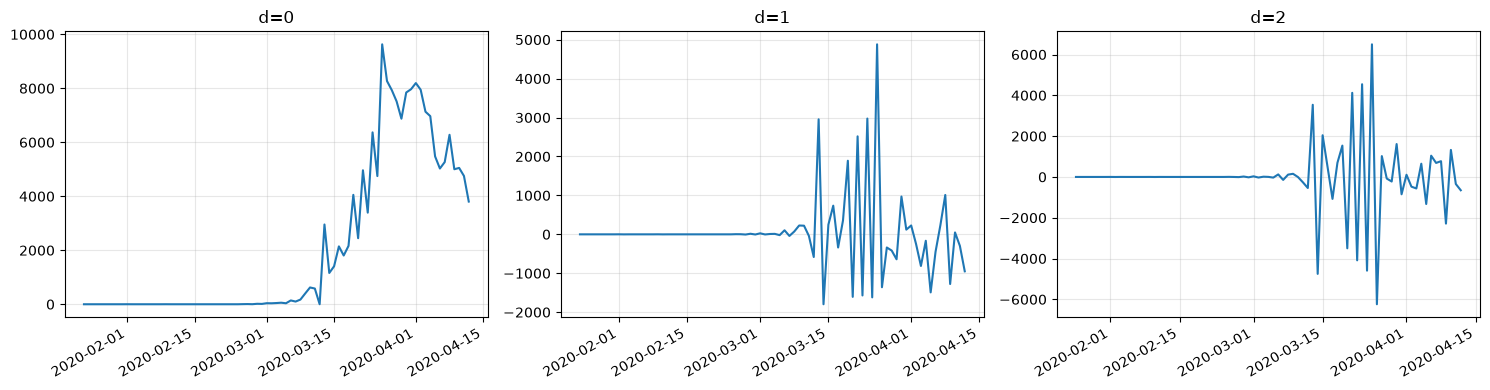

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = series.copy()
results = []

for ax, d in zip(axes.flat, range(3)):
    ax.plot(x.index, x)
    ax.set_title(f"d={d}")
    ax.grid(alpha=0.3)

    p_adf = test_stationarity(x)[0]
    p_kpss = test_stationarity(x)[1]
    results.append({"d": d, "p_adf": p_adf, "p_kpss": p_kpss})
    
    x = x.diff().dropna()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [36]:
result_table = pd.DataFrame(results).set_index("d")
display(result_table)

,p_adf,p_kpss
d,,
0,7.771420e-01,0.01
1,1.672001e-29,0.10
2,5.458349e-11,0.10


### Identification

## Prédiction avec VAR sur $X_t$

Pour un pays donné, on considère :

$$
X_t =
\begin{pmatrix}
\text{confirmed}_t \\
\text{deaths}_t \\
\text{recovered}_t
\end{pmatrix}
$$

On estime :

$$
\Delta X_t = c + \sum_{j=1}^{p} A_j \Delta X_{t-j} + \varepsilon_t
$$

Ce modèle est pertinent parce qu'il existe des liens épidémiologiques naturels entre ces variables :
- Les nouveaux décès dépendent en partie des contaminations antérieures.
- Les guérisons dépendent également des contaminations passées.
- Les trois séries reflètent différentes étapes d'une même dynamique épidémique.

Une autre idée serait d'exploiter les relations entre les dynamiques épidémiques nationales. Mais :
- Les épidémies ne démarrent pas au même moment selon les pays.
- Les dynamiques dépendent de politiques sanitaires, de pratiques de dépistage et de populations très différentes.
- Les relations temporelles entre pays ne sont pas nécessairement stables.
- Le nombre de paramètres devient important pour environ 80 observations.